# Rekomendasi musik Global Most Popular vs Personalized Most Popular Last.fm-1K 

Sumber: [rilis eifuentes/lastfm-dataset-1K](https://github.com/eifuentes/lastfm-dataset-1K/releases).

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from array import array
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import requests
import importlib.util, subprocess, sys
if importlib.util.find_spec('pyarrow') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'pyarrow'])
import pyarrow.parquet as pq

LOCAL_FILE = None  # contoh: '/kaggle/input/lastfm/lastfm-dataset-1k.snappy.parquet'
FILE_NAME = 'lastfm-dataset-1k.snappy.parquet'
EXAMPLE_USER = 'user_000001'
WINDOW = 150
EPS = 0.01
SEED = 42
KS = (5, 10, 40, 100)

## 1. Preparation
Mencari file full di input Kaggle, data/, atau direktori kerja. Jika belum ada, unduh aset resmi dari rilis repositori. File parsial hanya dipakai setelah lolos pemeriksaan ukuran dan metadata.

In [2]:
def resolve_source():
    if LOCAL_FILE:
        return Path(LOCAL_FILE).expanduser()
    for root in [Path('/kaggle/input'), Path('data')]:
        if root.exists():
            for p in root.rglob('*.parquet'):
                if p.name.lower() == FILE_NAME:
                    return p
    dest = Path(FILE_NAME)
    if dest.is_file():
        return dest
    api = 'https://api.github.com/repos/eifuentes/lastfm-dataset-1K/releases'
    response = requests.get(api, timeout=45)
    response.raise_for_status()
    assets = [a for rel in response.json() for a in rel['assets']
              if a['name'].lower() == FILE_NAME]
    if not assets:
        raise FileNotFoundError('Unduh Parquet full dari halaman Releases, lalu isi LOCAL_FILE.')
    asset = assets[0]
    tmp = dest.with_suffix('.part')
    print('Mengunduh', asset['name'], f"({asset['size']/1e6:.0f} MB)")
    with requests.get(asset['browser_download_url'], stream=True, timeout=(30, 180)) as r:
        r.raise_for_status()
        with tmp.open('wb') as out:
            for block in r.iter_content(2**20):
                out.write(block)
    if tmp.stat().st_size != asset['size']:
        raise OSError('Unduhan belum lengkap. Jalankan ulang sel.')
    pq.read_metadata(tmp)
    tmp.replace(dest)
    return dest

path = resolve_source()
pf = pq.ParquetFile(path)
print(path, '| baris sumber:', f'{pf.metadata.num_rows:,}')
if pf.metadata.num_rows < 10_000_000:
    raise ValueError('Input terlalu kecil untuk rilis penuh. Periksa file Parquet yang dipilih.')

Mengunduh lastfm-dataset-1k.snappy.parquet (877 MB)
lastfm-dataset-1k.snappy.parquet | baris sumber: 19,098,853


## 2. Preprocessing dan Global Temporal Split
Paper menggunakan 10% interaksi terakhir untuk test. Validasi menggunakan 128 pengguna dari periode sebelum test. Penilaian validasi hanya memakai histori sebelum batas validasi. Baseline final memakai data pra-uji. Sampel katalog paper_30k berbobot frekuensi global dan tanpa pengembalian.

In [3]:
def encode_batch(values, lookup):
    codes, names = pd.factorize(values, sort=False)
    ids = np.fromiter((lookup.setdefault(name, len(lookup)) for name in names),
                      dtype=np.int32, count=len(names))
    return ids[codes]

def load_events(batches):
    users, tracks = {}, {}
    ub, ib, tb = array('i'), array('i'), array('q')
    skipped = 0
    for df in batches:
        stamp = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
        valid = stamp.notna()
        for col in ['user_id', 'artist_name', 'track_name']:
            valid &= df[col].notna() & df[col].ne('')
        skipped += int((~valid).sum())
        df = df.loc[valid]
        ub.frombytes(encode_batch(df.user_id, users).tobytes())
        ib.frombytes(encode_batch(df.artist_name + ' - ' + df.track_name, tracks).tobytes())
        times = stamp.loc[valid].to_numpy(dtype='datetime64[ns]').view(np.int64)
        tb.frombytes(times.tobytes())
    return (np.frombuffer(ub, dtype=np.int32), np.frombuffer(ib, dtype=np.int32),
            np.frombuffer(tb, dtype=np.int64), users, tracks, skipped)

cols = ['user_id','timestamp','artist_name','track_name']
u, item, ts, users, tracks, skipped = load_events(
    b.to_pandas() for b in pf.iter_batches(batch_size=100_000, columns=cols))
if len(users) < 900:
    raise ValueError('Pengguna terlalu sedikit untuk Last.fm-1K penuh.')
assert len(ts) + skipped == pf.metadata.num_rows
original_size = len(ts)
freq = np.bincount(item, minlength=len(tracks)).astype(float)
if len(freq) < 30000:
    raise ValueError('Katalog perlu setidaknya 30.000 lagu.')
chosen = np.random.default_rng(SEED).choice(len(freq), 30000, replace=False, p=freq/freq.sum())
keep = np.isin(item, chosen)
u,item,ts = u[keep],item[keep],ts[keep]
catalog_size = len(np.unique(item))
ratio = 0.90
idx = int(len(ts)*ratio)
border = np.partition(ts,idx)[idx]
train = ts < border
print('| Baris valid sumber:',original_size,'| Baris eksperimen:',len(ts))
print('Pengguna:',len(np.unique(u)),'| Lagu:',catalog_size,'| Baris sumber dilewati:',skipped)
print('Batas uji UTC:',pd.to_datetime(border,utc=True),'| Pra-uji:',train.sum(),'| Uji:',(~train).sum())

| Baris valid sumber: 19098841 | Baris eksperimen: 4677041
Pengguna: 990 | Lagu: 30000 | Baris sumber dilewati: 12
Batas uji UTC: 2009-01-24 23:59:47+00:00 | Pra-uji: 4209336 | Uji: 467705


## 3. Global Most Popular dan PMP
Global MP menghitung seluruh data latih. PMP memakai hingga 150 interaksi latih terakhir per pengguna. Untuk frekuensi yang sama, PMP memakai urutan kemunculan pertama dalam jendela. Global MP memakai kode lagu sebagai pemecah seri.

Kolom probabilitas dan PPS adalah demonstrasi rumus. Normalisasi smoothing menggunakan seluruh katalog eksperimen pada mode full/paper_30k, dan lagu yang muncul dalam jendela pada teman_full. Peringkat PMP ditentukan dari frekuensi.

Pengguna contoh: user_000001 | Pengguna uji: 783
Pengguna uji tanpa riwayat latih: 48


,Lagu,Frekuensi,Probabilitas personal,PPS softmax,PPS sigmoid
0,Plaid - Takeshita Street,26,0.057800,0.000000,-2.791229
1,Plaid - Ishus,20,0.044467,-0.262249,-3.067530
2,London Elektricity - Uska,7,0.015578,-1.311143,-4.146209
3,Enya - One Toy Soldier [Album]/Album,6,0.013356,-1.465056,-4.302377
4,Loco Dice - La Esquina,5,0.011133,-1.647045,-4.486616


/tmp/ipykernel_23/2757141997.py:36: UserWarning: Glyph 12475 (\N{KATAKANA LETTER SE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2757141997.py:36: UserWarning: Glyph 12540 (\N{KATAKANA-HIRAGANA PROLONGED SOUND MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2757141997.py:36: UserWarning: Glyph 12501 (\N{KATAKANA LETTER HU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2757141997.py:36: UserWarning: Glyph 12539 (\N{KATAKANA MIDDLE DOT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2757141997.py:36: UserWarning: Glyph 12502 (\N{KATAKANA LETTER BU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2757141997.py:36: UserWarning: Glyph 12521 (\N{KATAKANA LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_23/2757141997.py:36: UserWarning: Glyph 12464 (\N{KATAKANA LETTER GU}) missing from font(s) DejaVu Sans.
  plt.tight_l

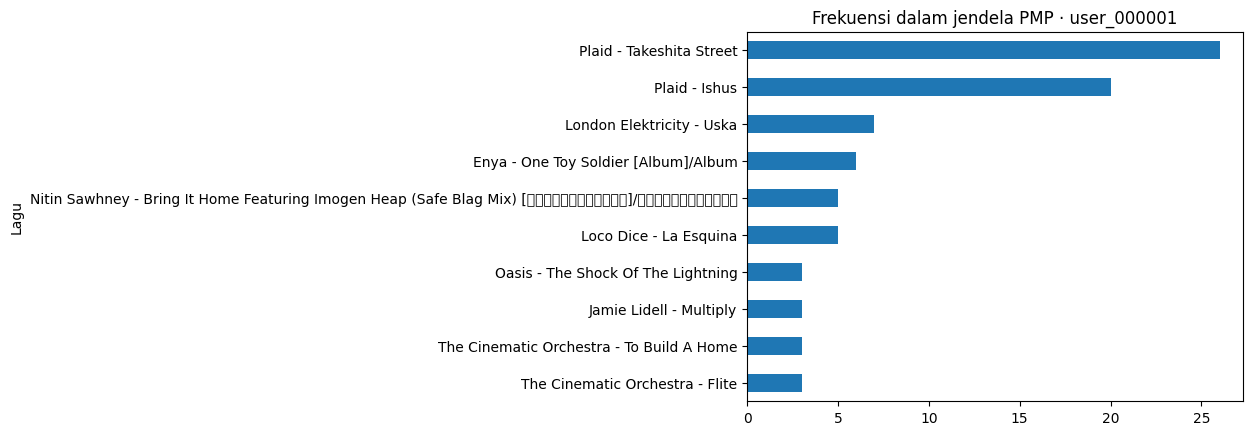

In [4]:
def build_models(u, item, ts, train, n_tracks):
    counts = np.bincount(item[train], minlength=n_tracks)
    seen = np.flatnonzero(counts)
    global_top = seen[np.argsort(-counts[seen], kind='stable')[:max(KS)]]
    order = np.lexsort((ts, u))
    bounds = np.r_[0, np.flatnonzero(np.diff(u[order])) + 1, len(order)]
    personal, truth = {}, {}
    for start, stop in zip(bounds[:-1], bounds[1:]):
        rows = order[start:stop]
        uid = int(u[rows[0]])
        hist = rows[train[rows]][-WINDOW:]
        personal[uid] = Counter(item[hist].tolist())
        future = rows[~train[rows]]
        if len(future):
            truth[uid] = set(item[future].tolist())
    return global_top.tolist(), personal, truth

global_top, personal, truth = build_models(u,item,ts,train,len(tracks))
names = list(tracks)
uid = users.get(EXAMPLE_USER)
if uid not in truth or not personal.get(uid):
    uid = next(i for i in truth if personal.get(i))
example = next(name for name, i in users.items() if i == uid)
print('Pengguna contoh:', example, '| Pengguna uji:',len(truth))
print('Pengguna uji tanpa riwayat latih:',sum(not personal[i] for i in truth))
ranking = personal[uid].most_common()
demo = pd.DataFrame([(names[i], n) for i,n in ranking],columns=['Lagu','Frekuensi'])
weights = demo.Frekuensi + EPS
demo['Probabilitas personal'] = p = weights / (sum(n for _,n in ranking) + EPS*catalog_size)
demo['PPS softmax'] = np.log(weights / weights.max())
clipped = p.clip(1e-12, 1-1e-12)
demo['PPS sigmoid'] = np.log(clipped/(1-clipped))
display(demo.head(5).round(6))
demo.head(10).sort_values('Frekuensi').plot.barh(x='Lagu',y='Frekuensi',legend=False,
    title='Frekuensi dalam jendela PMP · '+example)
plt.tight_layout()
plt.show()

## 4. NDCG dan perbandingan dengan seluruh pengguna uji
Relevansi 1 jika lagu muncul di periode uji pengguna. IDCG memakai jumlah lagu relevan unik hingga K. 

,Lagu,Relevansi,Kontribusi DCG
0,Plaid - Takeshita Street,1,1.000000
1,Plaid - Ishus,1,0.630930
2,London Elektricity - Uska,0,0.000000
3,Enya - One Toy Soldier [Album]/Album,1,0.430677
4,Loco Dice - La Esquina,1,0.386853


DCG@5=2.44846, IDCG@5=2.94846, NDCG@5=0.83042
Validasi: 128 pengguna | batas UTC: 2008-10-14 01:23:27+00:00


,Global MP,PMP,Perubahan (%)
K,,,
5,0.0943,0.5347,467.2033
10,0.1019,0.5107,401.0314
40,0.0967,0.4397,354.6258
100,0.0930,0.3760,304.2487


Hasil TEST: 783 pengguna


,Global MP,PMP,Perubahan (%)
K,,,
5,0.1036,0.5130,395.2344
10,0.0920,0.4865,428.7014
40,0.0882,0.3952,348.2563
100,0.0841,0.3371,300.6659


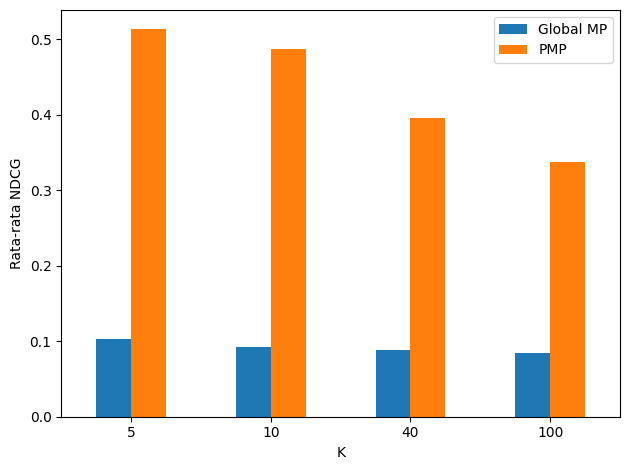

In [5]:
def evaluate_list(recs, relevant, k):
    hits = [int(i in relevant) for i in recs[:k]]
    terms = [hit/math.log2(rank+1) for rank,hit in enumerate(hits,1)]
    ideal = sum(1/math.log2(rank+1) for rank in range(1,min(k,len(relevant))+1))
    return hits, terms, ideal, sum(terms)/ideal if ideal else 0.0

top5 = [i for i,n in ranking[:5]]
hits, terms, ideal, score = evaluate_list(top5, truth[uid], 5)
display(pd.DataFrame({'Lagu':[names[i] for i in top5], 'Relevansi':hits,'Kontribusi DCG':terms}))
print(f'DCG@5={sum(terms):.5f}, IDCG@5={ideal:.5f}, NDCG@5={score:.5f}')

def compare(global_top, personal, truth):
    results = []
    for k in KS:
        mp_scores, pmp_scores = [], []
        for i, relevant in truth.items():
            rec = [track for track,n in personal[i].most_common(k)]
            mp_scores.append(evaluate_list(global_top,relevant,k)[-1])
            pmp_scores.append(evaluate_list(rec,relevant,k)[-1])
        mp, pmp = np.mean(mp_scores), np.mean(pmp_scores)
        results.append([k,mp,pmp,100*(pmp/mp-1) if mp else np.nan])
    return pd.DataFrame(results,columns=['K','Global MP','PMP','Perubahan (%)']).set_index('K')

pre_ts = ts[train]
cut = int(len(pre_ts)*0.9)
val_border = np.partition(pre_ts,cut)[cut]
vp = u[train]
eligible = np.unique(vp[pre_ts >= val_border])
selected = np.random.default_rng(SEED).choice(eligible,min(128,len(eligible)),replace=False)
vg, vh, vt = build_models(vp,item[train],pre_ts,pre_ts < val_border,len(tracks))
validation = compare(vg,vh,{i:vt[i] for i in selected})
print('Validasi:',len(selected),'pengguna | batas UTC:',pd.to_datetime(val_border,utc=True))
display(validation.round(4))
comparison = compare(global_top,personal,truth)
print('Hasil TEST:', len(truth),'pengguna')
display(comparison.round(4))
comparison[['Global MP','PMP']].plot.bar(ylabel='Rata-rata NDCG',rot=0)
plt.tight_layout()
plt.show()

In [6]:
from pathlib import Path

root = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
output = root / 'hasil_pmp' / 'paper'
output.mkdir(parents=True,exist_ok=True)

demo.head(5).to_csv(output / 'top5_pmp.csv', index=False)
pd.DataFrame({'Lagu': [names[i] for i in top5], 'Relevansi': hits,
              'Kontribusi DCG': terms}).to_csv(output / 'ndcg_manual.csv', index=False)
validation.to_csv(output / 'validasi_ndcg.csv')
comparison.to_csv(output / 'perbandingan_ndcg.csv')
pd.Series({'pengguna_contoh': example, 'pengguna_uji': len(truth), 'pengguna_validasi': len(selected), 'pengguna': len(np.unique(u)), 'lagu': catalog_size,
           'latih': int(train.sum()), 'uji': int((~train).sum()), 'dilewati': skipped,
           'batas_utc': str(pd.to_datetime(border, utc=True)), 'ndcg5_contoh': score}
          ).to_csv(output / 'ringkasan.csv', header=['nilai'])
for filename, ax in [
    ('frekuensi_top10.png', demo.head(10).sort_values('Frekuensi').plot.barh(
        x='Lagu', y='Frekuensi', legend=False, title='Frekuensi pemutaran · '+example)),
    ('perbandingan_ndcg.png', comparison[['Global MP','PMP']].plot.bar(
        ylabel='Rata-rata NDCG', rot=0))
]:
    ax.figure.savefig(output / filename, dpi=180, bbox_inches='tight')
    plt.close(ax.figure)
print('Hasil tersimpan di', output.resolve())
for file in sorted(output.iterdir()):
    print(file.name)

/tmp/ipykernel_23/2723958431.py:22: UserWarning: Glyph 12475 (\N{KATAKANA LETTER SE}) missing from font(s) DejaVu Sans.
  ax.figure.savefig(output / filename, dpi=180, bbox_inches='tight')
/tmp/ipykernel_23/2723958431.py:22: UserWarning: Glyph 12540 (\N{KATAKANA-HIRAGANA PROLONGED SOUND MARK}) missing from font(s) DejaVu Sans.
  ax.figure.savefig(output / filename, dpi=180, bbox_inches='tight')
/tmp/ipykernel_23/2723958431.py:22: UserWarning: Glyph 12501 (\N{KATAKANA LETTER HU}) missing from font(s) DejaVu Sans.
  ax.figure.savefig(output / filename, dpi=180, bbox_inches='tight')
/tmp/ipykernel_23/2723958431.py:22: UserWarning: Glyph 12539 (\N{KATAKANA MIDDLE DOT}) missing from font(s) DejaVu Sans.
  ax.figure.savefig(output / filename, dpi=180, bbox_inches='tight')
/tmp/ipykernel_23/2723958431.py:22: UserWarning: Glyph 12502 (\N{KATAKANA LETTER BU}) missing from font(s) DejaVu Sans.
  ax.figure.savefig(output / filename, dpi=180, bbox_inches='tight')
/tmp/ipykernel_23/2723958431.py:22

Hasil tersimpan di /kaggle/working/hasil_pmp/paper
frekuensi_top10.png
ndcg_manual.csv
perbandingan_ndcg.csv
perbandingan_ndcg.png
ringkasan.csv
top5_pmp.csv
validasi_ndcg.csv
